# Jagran Lakecity University
## Faculty of Science and Technology
### BTech CSE

---

## Practical Record: Assignment 3 - Module 3
### **Practical 10: Complete Genetic Algorithm Optimization System using DEAP**

| Academic Details | Information |
| :--- | :--- |
| **Course** | Soft Computing |
| **Module** | Module III: Genetic Algorithms and Evolutionary Computing |
| **Student Name** | *Aakash Sarang* |
| **Enrollment No.** | *2023BTCSE001* |
| **Academic Session** | 2026 – 2027 |

---

### 1. Aim
To design and implement a complete optimization system using a Genetic Algorithm in Python with the DEAP library by integrating population initialization, fitness evaluation, selection, crossover, mutation, and convergence analysis.

### 2. Theory: DEAP (Distributed Evolutionary Algorithms in Python)

DEAP provides modular building blocks (`creator`, `base.Toolbox`, `tools`, `algorithms`) for rapidly constructing evolutionary algorithms:
- `creator.create` defines custom fitness and individual types.
- `toolbox.register` binds initialization, evaluation, selection (`selTournament`), crossover (`cxTwoPoint`), and mutation (`mutFlipBit`).
- `tools.Statistics` and `tools.Logbook` record per-generation convergence metrics.

### 3. Step 1: Building and Running the DEAP Genetic Algorithm

Best Individual: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
Best Fitness:    30.0


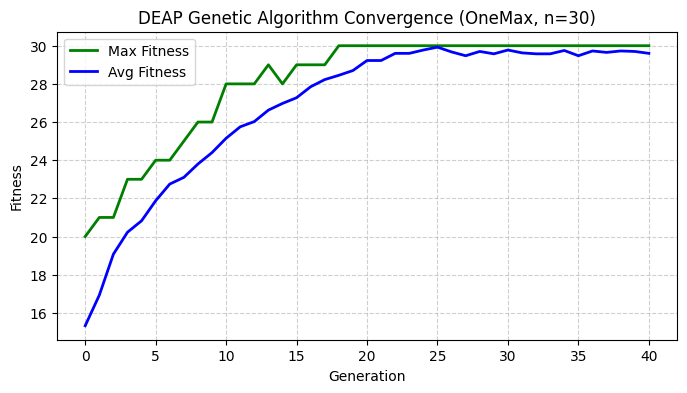

In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt
from deap import base, creator, tools, algorithms

random.seed(42)
np.random.seed(42)

# Define Fitness & Individual (safe against re-runs)
if not hasattr(creator, "FitnessMax"):
    creator.create("FitnessMax", base.Fitness, weights=(1.0,))
if not hasattr(creator, "Individual"):
    creator.create("Individual", list, fitness=creator.FitnessMax)

toolbox = base.Toolbox()
toolbox.register("attr_bool", random.randint, 0, 1)
toolbox.register("individual", tools.initRepeat, creator.Individual, toolbox.attr_bool, n=30)
toolbox.register("population", tools.initRepeat, list, toolbox.individual)

def eval_onemax(individual):
    return (sum(individual),)

toolbox.register("evaluate", eval_onemax)
toolbox.register("mate", tools.cxTwoPoint)
toolbox.register("mutate", tools.mutFlipBit, indpb=0.05)
toolbox.register("select", tools.selTournament, tournsize=3)

pop = toolbox.population(n=40)
hof = tools.HallOfFame(1)

stats = tools.Statistics(lambda ind: ind.fitness.values[0])
stats.register("avg", np.mean)
stats.register("min", np.min)
stats.register("max", np.max)

pop, logbook = algorithms.eaSimple(
    pop, toolbox, cxpb=0.7, mutpb=0.2, ngen=40, stats=stats, halloffame=hof, verbose=False
)

print("Best Individual:", hof[0])
print("Best Fitness:   ", hof[0].fitness.values[0])

gens = logbook.select("gen")
max_fits = logbook.select("max")
avg_fits = logbook.select("avg")

plt.figure(figsize=(8, 4))
plt.plot(gens, max_fits, label="Max Fitness", color="green", linewidth=2)
plt.plot(gens, avg_fits, label="Avg Fitness", color="blue", linewidth=2)
plt.title("DEAP Genetic Algorithm Convergence (OneMax, n=30)")
plt.xlabel("Generation")
plt.ylabel("Fitness")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

### 4. Conclusion
We designed and executed a complete GA optimization system using DEAP, integrating population initialization, fitness evaluation, tournament selection, two-point crossover, bit-flip mutation, Hall of Fame tracking, and convergence visualization.